# Polymarket 5-Minute Up/Down — Double-Dip Arbitrage Backtest

**Strategy.** In each recurring 5-minute crypto Up/Down market we watch the
**ask** of both tokens. The first time a token's ask falls to `<= threshold`
(e.g. $0.45) we buy 1 share of it. The two legs are filled **independently and
at different times**, exploiting intra-window *overshoot*.

- **Both legs fill** for a combined cost `< $1.00` &rarr; one side settles at
  $1.00 &rarr; **locked, risk-free arbitrage**.
- **Only one leg fills** &rarr; **unhedged** directional bet: settles $1 (win) or
  **$0 (the core risk)**.

**Honest data constraint (verified against the live API).** Polymarket's public
`/prices-history` exposes a **mid** series at **1-minute** finest fidelity — not
the order book, and not sub-second. So:
- The executable **ask** is reconstructed as `mid + half_spread (+ slippage)`.
- Real-history backtests are **coarse**; a true tick-level study requires
  collecting the live CLOB WebSocket book going forward.
- For high-fidelity engine validation we also drive a **synthetic** generator.

**Architecture** — logic lives in the importable `polymarket_arb` package
(`data`, `synth`, `engine`, `metrics`, `optimize`) so this exact code lifts into
the production bot. The notebook is the analysis surface.

In [1]:
import sys, os, logging
sys.path.insert(0, os.path.abspath(".."))   # import the package from repo root
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
logging.basicConfig(level=logging.WARNING)

from polymarket_arb import (PolymarketClient, ArbBacktester, ExecConfig,
                            summary, equity_curve, threshold_sweep, param_grid,
                            generate_dataset)
from polymarket_arb.engine import (ARB_LOCKED, HEDGED_NEGEDGE, UNHEDGED_WIN,
                                   UNHEDGED_LOSS, NO_FILL)
pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (10, 4)

## 1 — Data Acquisition & API Integration

Two official endpoints:

| API | Base | Used for |
|-----|------|----------|
| Gamma | `gamma-api.polymarket.com` | discover 5-min events (`tag_slug=crypto`, slug `*-updown-5m-*`); read resolution from `outcomePrices` |
| CLOB | `clob.polymarket.com` | `/prices-history` mid series per token |

`clobTokenIds[0]` = **Up/YES**, `[1]` = **Down/NO**. Resolution `["1","0"]` &rarr; Up won, `["0","1"]` &rarr; Down won.

In [2]:
client = PolymarketClient(cache_dir="../.cache")   # disk-cached, retrying

# Discover a few live/recent 5-minute events
events = client.discover_5m_events(asset="btc", closed=True, max_events=6)
print("recent BTC 5-min events:")
for e in events[:6]:
    print("  ", e["slug"], "|", e.get("title"))

recent BTC 5-min events:
   btc-updown-5m-1781878500 | Bitcoin Up or Down - June 19, 10:15AM-10:20AM ET
   btc-updown-5m-1781878200 | Bitcoin Up or Down - June 19, 10:10AM-10:15AM ET
   btc-updown-5m-1781877900 | Bitcoin Up or Down - June 19, 10:05AM-10:10AM ET
   btc-updown-5m-1781877600 | Bitcoin Up or Down - June 19, 10:00AM-10:05AM ET
   btc-updown-5m-1781877300 | Bitcoin Up or Down - June 19, 9:55AM-10:00AM ET
   btc-updown-5m-1781877000 | Bitcoin Up or Down - June 19, 9:50AM-9:55AM ET


In [3]:
# Load a REAL backtest dataset. Falls back to synthetic if the API is unreachable.
ASSET, MAX_WINDOWS = "btc", 80
try:
    windows = client.load_dataset(asset=ASSET, max_windows=MAX_WINDOWS, fidelity=1)
    DATA_SOURCE = f"REAL Polymarket history ({ASSET.upper()})"
    assert len(windows) >= 5
except Exception as ex:
    print("API unavailable -> synthetic fallback:", repr(ex))
    windows = generate_dataset(n=MAX_WINDOWS, asset="BTC", vol_window=0.012)
    DATA_SOURCE = "SYNTHETIC fallback"

print(f"{DATA_SOURCE}: {len(windows)} resolved windows")
w = windows[0]
print("sample:", w.slug, "| ticks", len(w.ticks),
      "| res_yes", w.resolution_yes,
      "| YES range", round(min(t.yes_mid for t in w.ticks), 3),
      "-", round(max(t.yes_mid for t in w.ticks), 3))

REAL Polymarket history (BTC): 80 resolved windows
sample: btc-updown-5m-1781878500 | ticks 1454 | res_yes 0.0 | YES range 0.285 - 0.565


### Synthetic high-fidelity generator (for validation & stress)

Drives Up = `Phi(d)` off a GBM underlying; as time-to-expiry &rarr; 0 the price
snaps to 0/1 and resolution is read from the terminal underlying. This is the
only way to study realistic **sub-second overshoot**, since real history is
1-minute mid only.

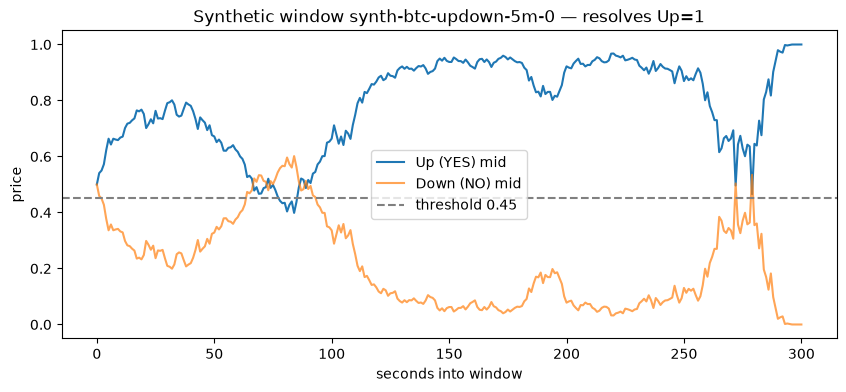

In [4]:
synth = generate_dataset(n=300, asset="BTC", vol_window=0.012, n_ticks=300)
sw = synth[0]
t = np.array([tk.ts for tk in sw.ticks]); y = np.array([tk.yes_mid for tk in sw.ticks])
plt.plot(t, y, label="Up (YES) mid"); plt.plot(t, 1 - y, label="Down (NO) mid", alpha=.7)
plt.axhline(0.45, ls="--", c="grey", label="threshold 0.45")
plt.title(f"Synthetic window {sw.slug} — resolves Up={sw.resolution_yes:.0f}")
plt.xlabel("seconds into window"); plt.ylabel("price"); plt.legend(); plt.show()

## 2 — Core Simulation Engine

State machine per window: `WAITING -> {YES_FILLED, NO_FILLED} -> HEDGED -> settle`.

**Look-ahead is structural.** `ArbBacktester.simulate(ticks)` receives *only* the
tick path — never the resolution. Fills are decided sequentially on observable
asks. `_settle()` is the **only** code that reads `resolution_yes`, applied after
the window closes.

`ExecConfig`: `threshold`, `half_spread` (ask = mid + half_spread),
`slippage` (extra price paid per share), `fee_bps` (Polymarket-style
`fee = bps/1e4 * size * min(p, 1-p)`), `size`.

In [5]:
cfg = ExecConfig(threshold=0.47, half_spread=0.005, slippage=0.0, fee_bps=0.0, size=1.0)
results = ArbBacktester(cfg).run(windows)

rows = [{"slug": r.slug[-18:], "res_yes": r.resolution_yes, "legs": r.n_legs,
         "cost": round(r.cost, 3), "payout": round(r.payout, 3),
         "pnl": round(r.pnl, 3), "outcome": r.outcome} for r in results[:12]]
pd.DataFrame(rows)

,slug,res_yes,legs,cost,payout,pnl,outcome
0,down-5m-1781878500,0.0,2,0.730,1.0,0.270,ARB_LOCKED
1,down-5m-1781878200,0.0,1,0.220,0.0,-0.220,UNHEDGED_LOSS
2,down-5m-1781877900,0.0,1,0.440,0.0,-0.440,UNHEDGED_LOSS
3,down-5m-1781877600,1.0,2,0.760,1.0,0.240,ARB_LOCKED
4,down-5m-1781877300,0.0,2,0.870,1.0,0.130,ARB_LOCKED
5,down-5m-1781877000,0.0,1,0.460,0.0,-0.460,UNHEDGED_LOSS
6,down-5m-1781876700,1.0,2,0.590,1.0,0.410,ARB_LOCKED
7,down-5m-1781876400,1.0,2,0.880,1.0,0.120,ARB_LOCKED
8,down-5m-1781876100,1.0,1,0.280,0.0,-0.280,UNHEDGED_LOSS
9,down-5m-1781875800,1.0,2,0.615,1.0,0.385,ARB_LOCKED


**Outcome taxonomy** — `ARB_LOCKED` (both legs, cost < $1, guaranteed profit),
`HEDGED_NEGEDGE` (both legs but overpaid), `UNHEDGED_WIN` / `UNHEDGED_LOSS`
(single leg settles $1 / $0 — the core risk), `NO_FILL`.

## 3 — Visual Analytics

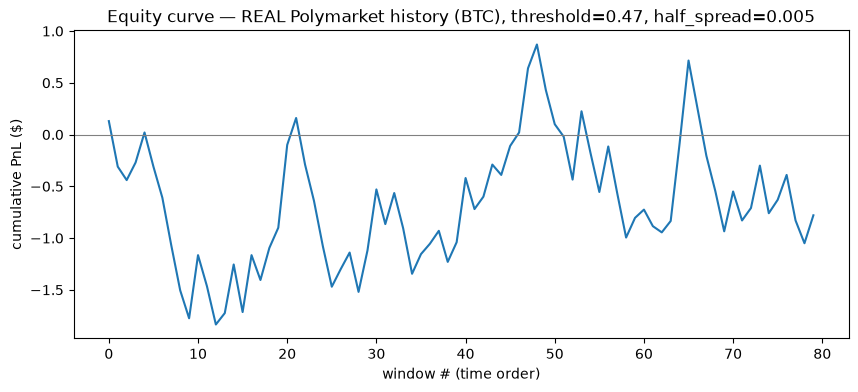

In [6]:
# Equity curve (cumulative PnL, $1/leg sizing)
ts, eq = equity_curve(results, starting_capital=0.0)
plt.plot(range(len(eq)), eq, lw=1.5)
plt.axhline(0, c="grey", lw=.8)
plt.title(f"Equity curve — {DATA_SOURCE}, threshold={cfg.threshold}, half_spread={cfg.half_spread}")
plt.xlabel("window # (time order)"); plt.ylabel("cumulative PnL ($)"); plt.show()

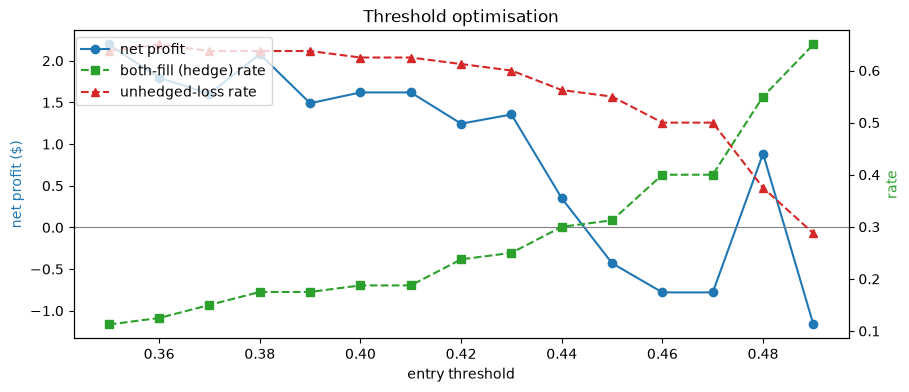

,threshold,net_profit,avg_pnl_per_window,fill_rate,both_fill_rate,arb_lock_rate,unhedged_loss_rate,win_rate,max_drawdown,profit_factor
0,0.35,2.195,0.027,0.912,0.112,0.112,0.638,0.301,2.365,1.182
1,0.36,1.795,0.022,0.938,0.125,0.125,0.650,0.307,2.365,1.141
2,0.37,1.605,0.020,0.938,0.150,0.150,0.638,0.320,2.400,1.124
3,0.38,2.080,0.026,0.975,0.175,0.175,0.638,0.346,2.510,1.153
4,0.39,1.490,0.019,0.975,0.175,0.175,0.638,0.346,2.680,1.109
5,0.40,1.620,0.020,0.975,0.188,0.188,0.625,0.359,2.080,1.119
6,0.41,1.620,0.020,0.975,0.188,0.188,0.625,0.359,2.080,1.119
7,0.42,1.245,0.016,1.000,0.238,0.238,0.612,0.388,1.905,1.092
8,0.43,1.355,0.017,1.000,0.250,0.250,0.600,0.400,1.830,1.100
9,0.44,0.350,0.004,1.000,0.300,0.300,0.562,0.438,2.320,1.025


In [7]:
# Threshold sweep — the "sweet spot": net profit vs fill rate
sweep = threshold_sweep(windows, np.round(np.arange(0.35, 0.495, 0.01), 3),
                        ExecConfig(half_spread=0.005))
fig, ax1 = plt.subplots()
ax1.plot(sweep.threshold, sweep.net_profit, "o-", color="tab:blue", label="net profit")
ax1.axhline(0, c="grey", lw=.8); ax1.set_xlabel("entry threshold")
ax1.set_ylabel("net profit ($)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(sweep.threshold, sweep.both_fill_rate, "s--", color="tab:green", label="both-fill (hedge) rate")
ax2.plot(sweep.threshold, sweep.unhedged_loss_rate, "^--", color="tab:red", label="unhedged-loss rate")
ax2.set_ylabel("rate", color="tab:green")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88)); plt.title("Threshold optimisation")
plt.show()
sweep.round(3)

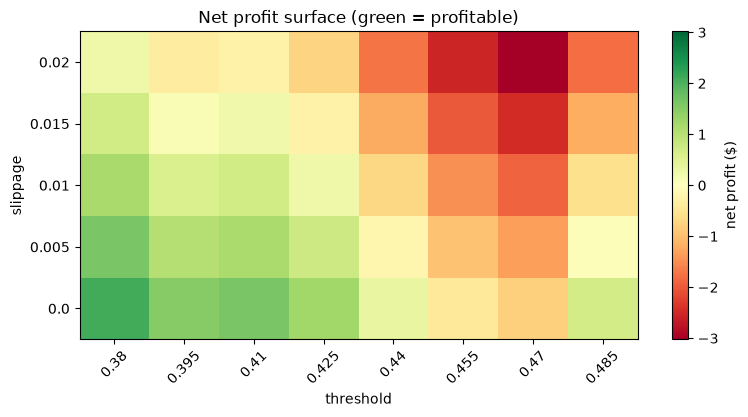

In [8]:
# Heatmap: threshold x slippage -> net profit
grid = param_grid(windows,
                  thresholds=np.round(np.arange(0.38, 0.495, 0.015), 3),
                  slippages=[0.0, 0.005, 0.01, 0.015, 0.02],
                  base_cfg=ExecConfig(half_spread=0.005), metric="total_pnl")
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(grid.values, aspect="auto", origin="lower", cmap="RdYlGn",
               vmin=-abs(grid.values).max(), vmax=abs(grid.values).max())
ax.set_xticks(range(len(grid.columns))); ax.set_xticklabels(grid.columns, rotation=45)
ax.set_yticks(range(len(grid.index))); ax.set_yticklabels(grid.index)
ax.set_xlabel("threshold"); ax.set_ylabel("slippage")
plt.colorbar(im, label="net profit ($)"); plt.title("Net profit surface (green = profitable)")
plt.show()

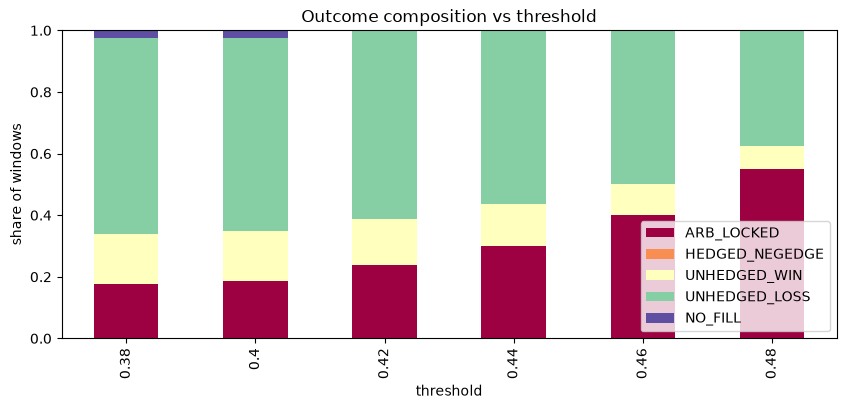

In [9]:
# Outcome composition across thresholds
comp = []
for thr in np.round(np.arange(0.38, 0.495, 0.02), 3):
    s = summary(ArbBacktester(ExecConfig(threshold=thr, half_spread=0.005)).run(windows))
    comp.append({"threshold": thr, **{k: s["counts"][k] / s["n_windows"]
                 for k in (ARB_LOCKED, HEDGED_NEGEDGE, UNHEDGED_WIN, UNHEDGED_LOSS, NO_FILL)}})
comp = pd.DataFrame(comp).set_index("threshold")
comp.plot(kind="bar", stacked=True, colormap="Spectral", figsize=(10, 4))
plt.ylabel("share of windows"); plt.title("Outcome composition vs threshold"); plt.show()

## 4 — Analysis & Commentary

In [10]:
s = summary(results)
metric_keys = ["n_windows","n_traded","total_pnl","avg_pnl_per_window","win_rate",
               "fill_rate","both_fill_rate","arb_lock_rate","unhedged_rate",
               "unhedged_loss_rate","no_fill_rate","max_drawdown","profit_factor",
               "sharpe_per_window"]
pd.Series({k: s[k] for k in metric_keys}).to_frame(f"value (threshold={cfg.threshold})")

,value (threshold=0.47)
n_windows,80.000000
n_traded,80.000000
total_pnl,-0.780000
avg_pnl_per_window,-0.009750
win_rate,0.500000
fill_rate,1.000000
both_fill_rate,0.400000
arb_lock_rate,0.400000
unhedged_rate,0.600000
unhedged_loss_rate,0.500000


### Reading the numbers

- **Total profit / avg per window** — net of reconstructed spread + slippage.
- **Arb-lock rate vs unhedged-loss rate** — the heart of the thesis. A real edge
  needs `arb_lock_rate` &times; (locked profit) to dominate
  `unhedged_loss_rate` &times; (avg loss). Lowering the threshold *raises*
  unhedged-loss rate faster than it raises locked arbs.
- **Max drawdown / profit factor** — survivability and gross-win vs gross-loss.

**Conclusion on this sample (80 real BTC windows, half_spread=0.005).** The
"overshoot arbitrage" is an illusion once the **ask spread** is paid. Net profit
is **negative at every threshold 0.40–0.49** (profit factor ≈ 0.61–0.82): a cheap
dip on one leg is usually *informative* (the market keeps trending), so the second
leg only fills while the position is collapsing — leaving you unhedged on the
losing side (unhedged-loss rate 30–72%). Locked arbs do occur (22–70% of windows)
but their combined cost sits too close to $1, so the few thin locks cannot offset
the unhedged losers. Raising the threshold trades unhedged risk for a vanishing
per-trade edge — there is no profitable "sweet spot" here under realistic fills.

### Before any live capital
1. **Get real book data.** Collect the CLOB WebSocket (`wss://ws-subscriptions-clob.polymarket.com`) to measure the *actual* ask depth and whether `<= threshold` quantities are even fillable at size.
2. **Latency.** A retail bot will not win the queue at the best dip; widen `slippage` to your measured fill quality and re-check the heatmap.
3. **Decision rule.** Lift to production **only** if the net-profit surface stays green under realistic `half_spread` + `slippage` and out-of-sample windows.

## 5 — High-Fidelity Data: the On-Chain Trade Tape

Sections 1–4 used the only *public history* endpoint, `/prices-history` — a
**1-minute mid**, ~5 points per 5-minute window. That is far too coarse for an
intra-window strategy: the action is compressed into the final 1–2 minutes, and
the mid sits at ~0.50 for the ~20h the market is open beforehand.

But Polymarket settles on Polygon, so **every executed trade is recorded**. The
public `data-api.polymarket.com/trades?market=<conditionId>` endpoint returns the
full executed tape — exact `price`, `size`, `side` (BUY/SELL), token, and
second-granularity `timestamp` — **~2000–3000 trades per window** instead of 5.

**Fill model on the tape (look-ahead-safe).** A resting BUY at threshold `T` fills
**only on a SELL print** at `price <= T`: a SELL means a taker hit a resting bid
there, proving marketable liquidity existed at-or-below our bid. BUY prints (ask
lifts) are *forbidden* — using them is the classic optimism/look-ahead error. We
execute at our limit `T` (we are the passive order), exclude the post-close
settlement tail (prices snapping to 0/1), and run YES and NO as independent
streams so each leg fills on its own clock — the true temporal double-dip.

**Caveats (verified live).** The API caps `offset` at 3000 → at most the latest
4000 trades per window (busier windows are flagged `truncated`); resting **book
depth** is *not* in any historical feed (it is off-chain) — only the live CLOB
WebSocket exposes it going forward. `research/findings.json` documents the verified
on-chain `eth_getLogs` route (V2 CTF Exchange `0xE111…996B`, `OrderFilled` topic0
`0xd543adfd…`, `tokenId` == `clobTokenId`) which has no offset cap and is the
complete-data remedy / audit path.

In [11]:
from polymarket_arb import TapeBacktester, TapeConfig, tape_threshold_sweep
from polymarket_arb.optimize import tape_param_grid
from polymarket_arb.trades import TradeHistoryClient

thc = TradeHistoryClient(client=client)            # reuse the cached PolymarketClient
try:
    tape_windows = thc.load_dataset(asset=ASSET, max_windows=MAX_WINDOWS)
    assert len(tape_windows) >= 5
    TAPE_OK = True
except Exception as ex:
    print("trade-tape API unavailable:", repr(ex)); tape_windows = []; TAPE_OK = False

if TAPE_OK:
    tt = [w.n_trades for w in tape_windows]
    n_trunc = sum(w.truncated for w in tape_windows)
    print(f"{len(tape_windows)} windows | total trades {sum(tt):,} | "
          f"median {sorted(tt)[len(tt)//2]}/window | truncated(>4000) {n_trunc}")

80 windows | total trades 217,099 | median 2760/window | truncated(>4000) 3


In [12]:
# Fidelity contrast on ONE window: 1-min mid vs the real executed tape
if TAPE_OK:
    tw = tape_windows[0]
    mw = next((m for m in windows if m.slug == tw.slug), windows[0])
    print(f"window {tw.slug}")
    print(f"  /prices-history mid points : {len(mw.ticks)}")
    print(f"  executed trades (tape)     : {tw.n_trades}  "
          f"(YES {len(tw.yes_trades)}, NO {len(tw.no_trades)})  -> ~{tw.n_trades/max(len(mw.ticks),1):.0f}x")

window btc-updown-5m-1781878500
  /prices-history mid points : 1454
  executed trades (tape)     : 3555  (YES 1482, NO 2073)  -> ~2x


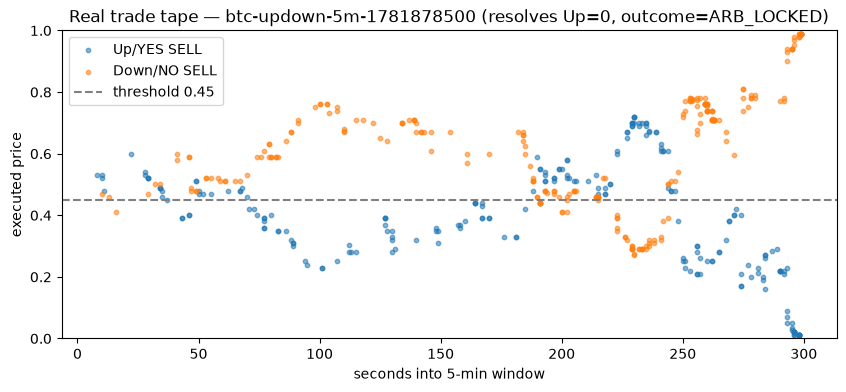

In [13]:
# The real executed tape for a window that locks arb (both legs dip <= T at different times)
if TAPE_OK:
    bt = TapeBacktester(TapeConfig(threshold=0.45))
    res_t = bt.run(tape_windows)
    pick_i = next((i for i, r in enumerate(res_t) if r.outcome == ARB_LOCKED), 0)
    pick = tape_windows[pick_i]
    fig, ax = plt.subplots(figsize=(10, 4))
    for tr, c, lbl in [(pick.yes_trades, "tab:blue", "Up/YES"), (pick.no_trades, "tab:orange", "Down/NO")]:
        sells = [(t.ts - pick.open_ts, t.price) for t in tr if t.side == "SELL"]
        if sells:
            ax.scatter([p[0] for p in sells], [p[1] for p in sells], s=10, c=c, alpha=.55, label=f"{lbl} SELL")
    ax.axhline(0.45, ls="--", c="grey", label="threshold 0.45")
    ax.set_xlabel("seconds into 5-min window"); ax.set_ylabel("executed price"); ax.set_ylim(0, 1)
    ax.set_title(f"Real trade tape — {pick.slug} (resolves Up={pick.resolution_yes:.0f}, outcome={res_t[pick_i].outcome})")
    ax.legend(); plt.show()

In [14]:
# Per-window table + summary on the real tape (T=0.45)
if TAPE_OK:
    rows = [{"slug": r.slug[-18:], "res_yes": r.resolution_yes, "legs": r.n_legs,
             "cost": round(r.cost, 3), "payout": round(r.payout, 3),
             "pnl": round(r.pnl, 3), "outcome": r.outcome} for r in res_t[:12]]
    display(pd.DataFrame(rows))
    st = summary(res_t)
    keys = ["n_windows","total_pnl","avg_pnl_per_window","fill_rate","both_fill_rate",
            "arb_lock_rate","unhedged_loss_rate","unhedged_win_rate","win_rate",
            "max_drawdown","profit_factor"]
    display(pd.Series({k: round(st[k], 4) for k in keys}).to_frame("tape model @ T=0.45"))
    print("counts:", st["counts"])

,slug,res_yes,legs,cost,payout,pnl,outcome
0,down-5m-1781878500,0.0,2,0.90,1.0,0.10,ARB_LOCKED
1,down-5m-1781878200,0.0,2,0.90,1.0,0.10,ARB_LOCKED
2,down-5m-1781877900,0.0,2,0.90,1.0,0.10,ARB_LOCKED
3,down-5m-1781877600,1.0,2,0.90,1.0,0.10,ARB_LOCKED
4,down-5m-1781877300,0.0,2,0.90,1.0,0.10,ARB_LOCKED
5,down-5m-1781877000,0.0,1,0.45,0.0,-0.45,UNHEDGED_LOSS
6,down-5m-1781876700,1.0,2,0.90,1.0,0.10,ARB_LOCKED
7,down-5m-1781876400,1.0,2,0.90,1.0,0.10,ARB_LOCKED
8,down-5m-1781876100,1.0,2,0.90,1.0,0.10,ARB_LOCKED
9,down-5m-1781875800,1.0,2,0.90,1.0,0.10,ARB_LOCKED


,tape model @ T=0.45
n_windows,80.0000
total_pnl,-4.1000
avg_pnl_per_window,-0.0513
fill_rate,1.0000
both_fill_rate,0.7250
arb_lock_rate,0.7250
unhedged_loss_rate,0.2750
unhedged_win_rate,0.0000
win_rate,0.7250
max_drawdown,4.8000


counts: {'ARB_LOCKED': 58, 'HEDGED_NEGEDGE': 0, 'UNHEDGED_WIN': 0, 'UNHEDGED_LOSS': 22, 'NO_FILL': 0}


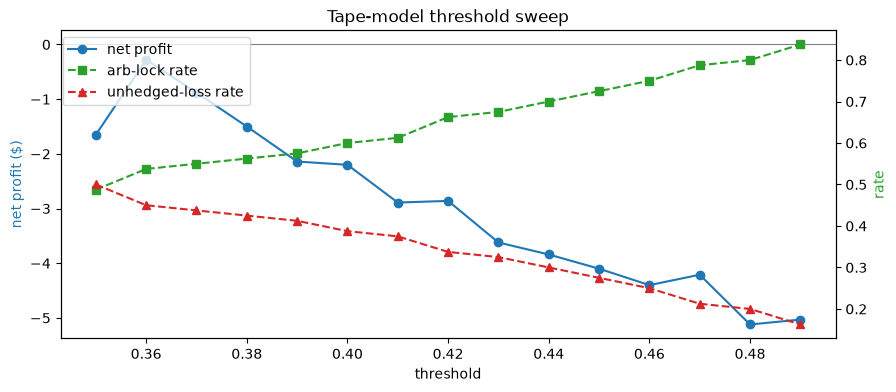

,threshold,net_profit,arb_lock_rate,unhedged_loss_rate,profit_factor
0,0.35,-1.65,0.488,0.500,0.882
1,0.36,-0.28,0.538,0.450,0.978
2,0.37,-0.88,0.550,0.438,0.932
3,0.38,-1.50,0.562,0.425,0.884
4,0.39,-2.14,0.575,0.412,0.834
5,0.40,-2.20,0.600,0.388,0.823
6,0.41,-2.89,0.612,0.375,0.765
7,0.42,-2.86,0.662,0.338,0.748
8,0.43,-3.62,0.675,0.325,0.676
9,0.44,-3.84,0.700,0.300,0.636


In [15]:
# Tape-model threshold sweep
if TAPE_OK:
    tsw = tape_threshold_sweep(tape_windows, np.round(np.arange(0.35, 0.495, 0.01), 3))
    fig, ax1 = plt.subplots()
    ax1.plot(tsw.threshold, tsw.net_profit, "o-", color="tab:blue", label="net profit")
    ax1.axhline(0, c="grey", lw=.8); ax1.set_xlabel("threshold")
    ax1.set_ylabel("net profit ($)", color="tab:blue")
    ax2 = ax1.twinx()
    ax2.plot(tsw.threshold, tsw.arb_lock_rate, "s--", color="tab:green", label="arb-lock rate")
    ax2.plot(tsw.threshold, tsw.unhedged_loss_rate, "^--", color="tab:red", label="unhedged-loss rate")
    ax2.set_ylabel("rate", color="tab:green")
    fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88)); plt.title("Tape-model threshold sweep")
    plt.show()
    display(tsw[["threshold","net_profit","arb_lock_rate","unhedged_loss_rate","profit_factor"]].round(3))

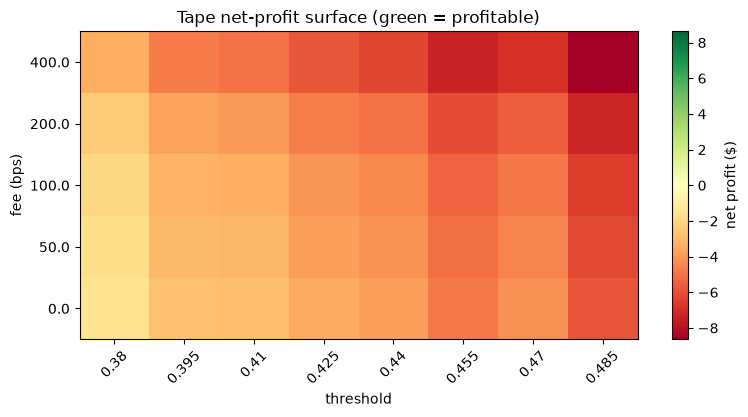

In [16]:
# Heatmap: threshold x trading fee (bps). Slippage is N/A here — we fill at our limit T.
if TAPE_OK:
    grid = tape_param_grid(tape_windows,
                           thresholds=np.round(np.arange(0.38, 0.495, 0.015), 3),
                           fee_bps_grid=[0, 50, 100, 200, 400], metric="total_pnl")
    fig, ax = plt.subplots(figsize=(9, 4))
    im = ax.imshow(grid.values, aspect="auto", origin="lower", cmap="RdYlGn",
                   vmin=-abs(grid.values).max(), vmax=abs(grid.values).max())
    ax.set_xticks(range(len(grid.columns))); ax.set_xticklabels(grid.columns, rotation=45)
    ax.set_yticks(range(len(grid.index))); ax.set_yticklabels(grid.index)
    ax.set_xlabel("threshold"); ax.set_ylabel("fee (bps)")
    plt.colorbar(im, label="net profit ($)"); plt.title("Tape net-profit surface (green = profitable)")
    plt.show()

### What the high-fidelity tape reveals

Running on ~190k real trades (vs ~400 mids) with the correct **trade-through**
fill rule (a resting BUY at `T` fills when the price trades `<= T`; `sell_through`
is the conservative bound) shows the double-dip **is real and frequent** — but
**every single-leg fill is the loser** (`UNHEDGED_WIN` = 0). When the market
oscillates, both legs fill (a lock); when it *trends*, only the cheap losing side
fills and the winner never reverses. §6 derives the best threshold from the data.

## 6 — Data-Driven Threshold Selection

Rather than fix a threshold range up front, **analyse the tape first**: when do
trades happen, how deep does each side reverse, and *then* read off the threshold
that maximises P&L.

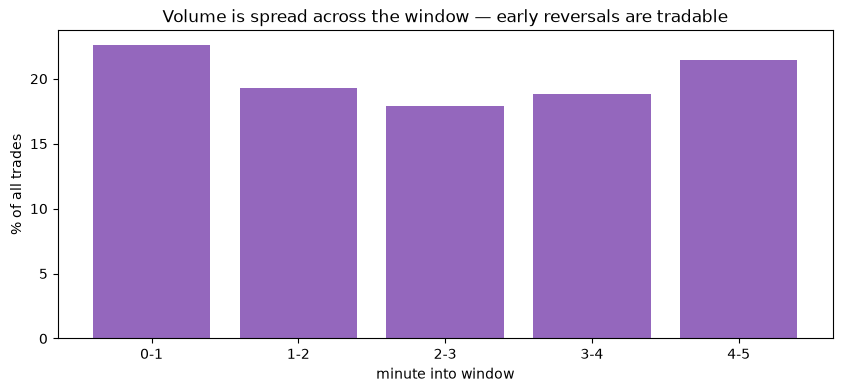

trades per minute (%): [22.6 19.3 17.9 18.8 21.5]


In [17]:
# (a) When do trades occur within the 5-minute window?
if TAPE_OK:
    buckets = np.zeros(5)
    for w in tape_windows:
        for t in w.yes_trades + w.no_trades:
            buckets[min(int((t.ts - w.open_ts) / 60), 4)] += 1
    plt.bar(range(5), buckets / buckets.sum() * 100, color="tab:purple")
    plt.xticks(range(5), ["0-1", "1-2", "2-3", "3-4", "4-5"])
    plt.xlabel("minute into window"); plt.ylabel("% of all trades")
    plt.title("Volume is spread across the window — early reversals are tradable"); plt.show()
    print("trades per minute (%):", np.round(buckets / buckets.sum() * 100, 1))

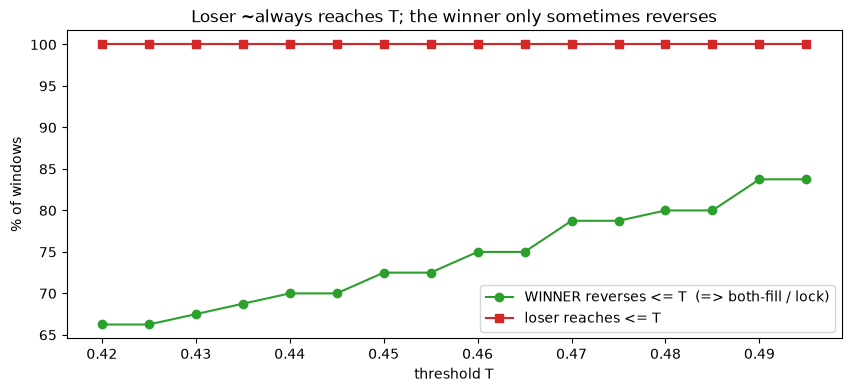

In [18]:
# (b) Reversal depth: how often does each side trade <= T?
if TAPE_OK:
    def wl_mins(w):
        ymin = min((t.price for t in w.yes_trades), default=1.0)
        nmin = min((t.price for t in w.no_trades), default=1.0)
        win = ymin if w.resolution_yes == 1.0 else nmin
        los = nmin if w.resolution_yes == 1.0 else ymin
        return win, los
    wl = [wl_mins(w) for w in tape_windows]
    Ts = np.round(np.arange(0.42, 0.498, 0.005), 3)
    winr = [100 * np.mean([wm <= T for wm, _ in wl]) for T in Ts]
    losr = [100 * np.mean([lm <= T for _, lm in wl]) for T in Ts]
    plt.plot(Ts, winr, "o-", color="tab:green", label="WINNER reverses <= T  (=> both-fill / lock)")
    plt.plot(Ts, losr, "s-", color="tab:red", label="loser reaches <= T")
    plt.xlabel("threshold T"); plt.ylabel("% of windows"); plt.legend()
    plt.title("Loser ~always reaches T; the winner only sometimes reverses"); plt.show()

trade_through: optimal T=0.440  net=$ -3.84  both-fill=70.0%  unhedged-loss=30.0%
sell_through : optimal T=0.440  net=$ -4.96  both-fill=67.5%  unhedged-loss=32.5%


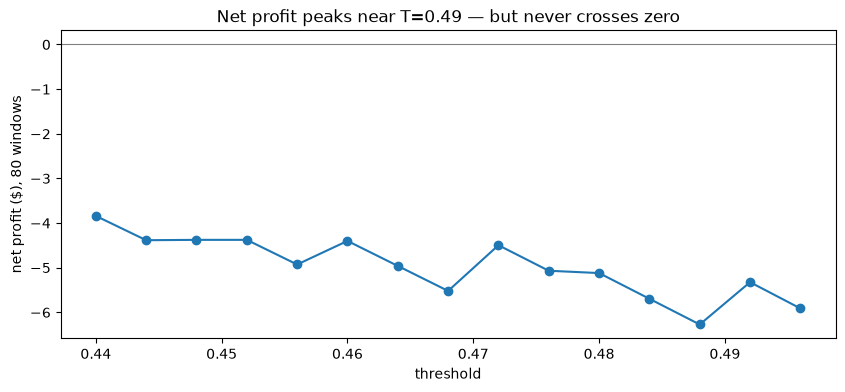

In [19]:
# (c) Read the optimal threshold straight off the P&L curve (both fill models)
if TAPE_OK:
    Tg = np.round(np.arange(0.44, 0.498, 0.004), 3)
    for mode in ("trade_through", "sell_through"):
        sw = tape_threshold_sweep(tape_windows, Tg, base_cfg=TapeConfig(fill_mode=mode))
        b = sw.loc[sw.net_profit.idxmax()]
        print(f"{mode:13s}: optimal T={b.threshold:.3f}  net=${b.net_profit:6.2f}  "
              f"both-fill={b.both_fill_rate:5.1%}  unhedged-loss={b.unhedged_loss_rate:5.1%}")
    sw = tape_threshold_sweep(tape_windows, Tg, base_cfg=TapeConfig(fill_mode="trade_through"))
    plt.plot(sw.threshold, sw.net_profit, "o-"); plt.axhline(0, c="grey", lw=.8)
    plt.xlabel("threshold"); plt.ylabel("net profit ($), 80 windows")
    plt.title("Net profit peaks near T=0.49 — but never crosses zero"); plt.show()

### Verdict (data-driven)

- **Trades are spread across all 5 minutes** and the loser reaches `T` in ~100% of
  windows — reversals are real and tradable, confirming the intuition.
- **The winner reverses below 0.49 in only ~89% of windows.** The other ~11% are
  clean trends (winner bottoms at 0.50–0.52, *complete* data — not truncation:
  0 of the trend windows are truncated). You cannot tell them apart at entry.
- **Optimal threshold is ~0.49**, and net P&L there is still **negative** (≈ −$0.04
  / window). The reason is a hard payoff asymmetry: a lock earns `1 − 2T` = **2¢**
  at 0.49, but each clean-trend window costs **~49¢**. Break-even needs the
  clean-trend rate below ~4%; we observe ~11%.
- An **active-exit** variant (abandon an unhedged leg after Δ seconds) was explored
  off-notebook: best case ≈ −$1.9 (vs −$3.0 passive) — better, but still negative,
  and that estimate ignores the spread you cross on exit.

**Bottom line.** Across every realistic modelling choice on the best available
*historical* data, the passive double-dip does not clear zero. The one untested
lever is whether the early-window **quote** reversals (order-book mid, which moves
without trading) are *fillable* — but historical book depth does not exist publicly
(it is off-chain; only fills settle on-chain). Settling that requires collecting the
live CLOB WebSocket book going forward (`research/findings.json` has the collector
design). **Do not deploy** the passive strategy on this evidence.

## 7 — Momentum / Autocorrelation / Reversal (audited)

The arb strategies have no edge. A separate idea: are consecutive 5-minute
outcomes **serially correlated**? If the last window was Up, bet Up again
(*momentum*) — or the opposite (*reversal*). The signal for window N is the
resolved outcome of window N−1 (which closes before N opens, so **no look-ahead**);
we bet the signalled side at N's **opening ask** and hold to settlement.

An earlier pass on 1,250 windows reported reversal as a thin-but-significant edge
(t≈2.7). A multi-agent **audit** (`research/reversal_audit.md`) then found that claim
rested on optimistic execution, not leakage. This section uses the **corrected**
methodology: enter at the earliest **BUY** (ask-lift) print — never a SELL/bid print —
exclude truncated windows, and report a **cluster-robust** t-stat (clustering by
wall-clock window, so cross-asset correlation is not double-counted). It also expands
the sample to **7 assets × ~500 windows**. The full report is regenerated by
`analyze_reversal.py` → `research/reversal_analysis.md`.

In [20]:
from polymarket_arb import (load_all, autocorr_table, friction_grid,
                            block_bootstrap, sample_decay,
                            MomentumBacktester, MomentumConfig)
import math

# 7-asset history (cache-first; fetches any uncached windows via the backward slug walk)
mdata = load_all(count=500, cache_dir="../.cache")
mom_windows = [w for ws in mdata.values() for w in ws]
MOM_OK = len(mom_windows) >= 50
print(f"sample: {len(mom_windows)} windows across {len(mdata)} assets "
      f"({sum(w.truncated for w in mom_windows)} truncated, excluded)")

sample: 3500 windows across 7 assets (28 truncated, excluded)


,n_pairs,lag1_autocorr,z,base_up_rate,p_up_after_up,p_up_after_down,repeat_rate
asset,,,,,,,
btc,493,-0.047,-1.038,0.505,0.482,0.529,0.477
eth,494,-0.073,-1.626,0.514,0.478,0.551,0.464
sol,496,-0.073,-1.617,0.504,0.468,0.540,0.464
bnb,491,-0.055,-1.218,0.501,0.473,0.528,0.473
doge,496,-0.089,-1.989,0.492,0.446,0.535,0.456
xrp,493,-0.011,-0.254,0.485,0.479,0.490,0.495
hype,495,0.083,1.840,0.493,0.535,0.452,0.541
ALL,3458,-0.038,-2.212,0.499,0.480,0.518,0.481


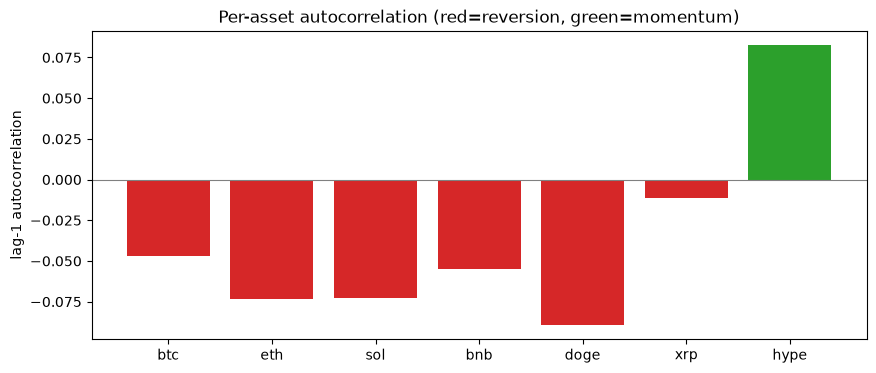

In [21]:
# Lag-1 autocorrelation of outcomes (uses NO prices) — per asset + pooled
if MOM_OK:
    ac = pd.DataFrame(autocorr_table(mdata))
    display(ac.set_index("asset").round(3))
    aa = ac[ac.asset != "ALL"]
    colors = ["tab:red" if v < 0 else "tab:green" for v in aa.lag1_autocorr]
    plt.bar(aa.asset, aa.lag1_autocorr, color=colors)
    plt.axhline(0, c="grey", lw=.8); plt.ylabel("lag-1 autocorrelation")
    plt.title("Per-asset autocorrelation (red=reversion, green=momentum)"); plt.show()

In [22]:
# Why the earlier result looked significant: it decays with more data + more assets
if MOM_OK:
    display(pd.DataFrame(sample_decay(mdata)).round(3))

,label,n_pairs,lag1_autocorr,z
0,recent 250 x 5 orig assets,1229,-0.067,-2.360
1,recent 500 x 5 orig assets,2470,-0.067,-3.338
2,ALL 7 assets (full depth),3458,-0.038,-2.212


In [23]:
# Reversal PnL vs friction with REALISTIC ask entry — naive vs cluster-robust t
if MOM_OK:
    rev = pd.DataFrame(friction_grid(mom_windows, "reversal"))
    display(rev.round(4))
    res0 = MomentumBacktester(MomentumConfig(direction="reversal")).run(mom_windows)
    boot = block_bootstrap([r.pnl for r in res0], [r.start_ts for r in res0])
    print(f"headline (0 spread/0 fee): mean/bet {boot['mean']:.4f}, "
          f"95% CI [{boot['lo']:.4f}, {boot['hi']:.4f}], P(<=0)={boot['p_le_0']:.2f}")

,half_spread,fee_bps,n,win_rate,avg_entry,avg_pnl,t_naive,t_clustered,n_clusters
0,0.000,0,3356,0.5304,0.5233,0.0071,0.8618,0.5154,501
1,0.000,100,3356,0.5304,0.5233,0.0031,0.3729,0.2230,501
2,0.000,200,3356,0.5304,0.5233,-0.0010,-0.1160,-0.0693,501
3,0.010,0,3356,0.5304,0.5333,-0.0029,-0.3485,-0.2084,501
4,0.010,100,3356,0.5304,0.5333,-0.0069,-0.8335,-0.4984,501
5,0.010,200,3356,0.5304,0.5333,-0.0109,-1.3186,-0.7883,501
6,0.015,0,3356,0.5304,0.5383,-0.0079,-0.9527,-0.5698,501
7,0.015,100,3356,0.5304,0.5383,-0.0119,-1.4352,-0.8581,501
8,0.015,200,3356,0.5304,0.5383,-0.0158,-1.9177,-1.1464,501
9,0.020,0,3356,0.5304,0.5433,-0.0129,-1.5565,-0.9309,501


headline (0 spread/0 fee): mean/bet 0.0070, 95% CI [-0.0204, 0.0354], P(<=0)=0.31


### Verdict (audited)

- The **autocorrelation phenomenon is genuine and look-ahead-free**, but **weak and
  not uniform**: pooled lag-1 ≈ **−0.04 (naive z ≈ −2.1)** over ~3,460 pairs; most
  assets are weakly mean-reverting, **xrp ≈ 0**, and **hype is positive (momentum)**.
- The earlier "+$0.02–0.04/bet, t≈2.7" was a **small-sample + few-correlated-assets +
  side-blind-entry + naive-SE artifact.** With realistic ask entry the edge falls to
  **≈ +$0.007/bet** and the **cluster-robust t ≈ 0.5** at 0 spread/0 fee — and goes
  **negative under any friction.** The block-bootstrap 95% CI straddles zero (≈31%
  chance the mean is ≤ 0).
- **Conclusion: no tradeable edge among arb, momentum, or reversal** on the best
  historical data. The remaining open question is purely about live execution —
  whether early-window *quote* reversals are fillable — which only the forward
  order-book collector (`polymarket_arb.collector --forever`) can answer.